# **Project Name**    - E-Commerce Customer Satisfaction (CSAT): Exploratory Data Analysis of Shopzilla Support Tickets

##### **Project Type**    - EDA
##### **Contribution**    - Individual / Team
##### **Team Member 1 -** <add name>
##### **Team Member 2 -** <add name>
##### **Team Member 3 -** <add name>
##### **Team Member 4 -** <add name>

# **Project Summary -**

This project is an exploratory analysis of **85,907 customer-support tickets** handled by the e-commerce platform Shopzilla over one month (28 Jul - 31 Aug 2023), each with the customer's satisfaction (CSAT) score from 1 to 5. The goal is to understand *what drives satisfaction* so the business can act on it, and to prepare the ground for a CSAT prediction model.

**Data quality.** There are no duplicate rows and the target has no missing values. Missingness is structural: about 80 % of tickets are not linked to an order, so order date, price, product and city are empty by design, and `connected_handling_time` is 99.7 % missing and was dropped. The timestamps were stored as text in two formats and were parsed; 3,128 rows (3.6 %) show a response logged before the report and were clipped to zero and flagged.

**Key findings.** CSAT is J-shaped: 69.4 % of customers give 5, 13.1 % give 1 and the middle scores are rare, so customers are polarised. We call a ticket *dissatisfied* when CSAT <= 2 (14.6 %).
* **Speed matters most.** Dissatisfaction rises from 8.9 % when the first answer arrives within 5 minutes to 36.3 % beyond 24 hours; the correlation with CSAT is the strongest of any numeric feature (Spearman -0.18).
* **E-mail is the weak channel** (23.2 % dissatisfied vs about 14 % on phone), especially for returns and payments.
* **Order-linked tickets are unhappier** (21.5 % vs 12.8 %), most of all for Furniture, Mobile and Home Appliances (about 30 %) and for sub-categories such as Seller Cancelled Order (30 %), Not Needed (23 %) and Installation/demo (23 %); Return requests are the happiest (5.5 %).
* **People factors:** trainee agents (16.6 %) and the Morning shift (15.8 %) are weaker, the spread between agents is about twice what chance would produce, and the best-to-worst manager gap is 6 points.
* **Time:** satisfaction improved over the month (about 15 % dissatisfied in week 1 to about 13 % in the last week), while hour of day and weekday matter very little.

**Business recommendations.** Set and monitor a first-response SLA (about 15 minutes) with escalation of tickets that age, fix e-mail handling, give structured support to trainee agents and the Morning shift, create specialised flows for bulky/high-value products and for seller cancellations, and learn from the best-performing managers and the improvement seen late in the month. The analysis also shows that a large share of dissatisfaction cannot be explained by ticket metadata alone, which is why an earlier voice-of-customer signal would be the most valuable addition for any future predictive model.

# **GitHub Link -**

<paste your GitHub repository link here>

# **Problem Statement**

**Shopzilla's support team handles tens of thousands of tickets a month, but leadership only sees an average CSAT figure. It does not know which channels, issue types, products, teams and operational behaviours (especially response speed) create dissatisfied customers, or where a limited improvement budget would pay off most. This project analyses one month of tickets to find those drivers and turn them into concrete recommendations.**

#### **Define Your Business Objective?**

1. Describe how satisfaction is distributed and where data quality limits the analysis.
2. Identify the operational, product, issue-type and people-related factors associated with *dissatisfied* customers (CSAT <= 2).
3. Quantify each effect with sample sizes and confidence intervals so that decisions are not based on small-sample noise.
4. Recommend specific, prioritised actions that raise CSAT and lower the share of dissatisfied customers.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, warnings, random
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE, GREY, RED = "#2f6db5", "#e8833a", "#8c8c8c", "#c0392b"
pd.set_option("display.max_columns", 50)
print("pandas", pd.__version__)

pandas 3.0.2


### Dataset Loading

In [2]:
# Load Dataset (works locally, in the project sandbox and in Google Colab)
CANDIDATE_PATHS = ["/mnt/user-data/uploads/eCommerce_Customer_support_data.csv",
                   "eCommerce_Customer_support_data.csv", "data/eCommerce_Customer_support_data.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:                                # Colab fallback: ask for an upload
    try:
        from google.colab import files
        files.upload(); DATA_PATH = "eCommerce_Customer_support_data.csv"
    except ImportError:
        raise FileNotFoundError("Place eCommerce_Customer_support_data.csv next to this notebook.")
raw = pd.read_csv(DATA_PATH)
print("Loaded from:", DATA_PATH)

Loaded from: /mnt/user-data/uploads/eCommerce_Customer_support_data.csv


### Dataset First View

In [3]:
# Dataset First Look
raw.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")

Rows: 85,907 | Columns: 20


### Dataset Information

In [5]:
# Dataset Info
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  str    
 1   channel_name             85907 non-null  str    
 2   category                 85907 non-null  str    
 3   Sub-category             85907 non-null  str    
 4   Customer Remarks         28742 non-null  str    
 5   Order_id                 67675 non-null  str    
 6   order_date_time          17214 non-null  str    
 7   Issue_reported at        85907 non-null  str    
 8   issue_responded          85907 non-null  str    
 9   Survey_response_Date     85907 non-null  str    
 10  Customer_City            17079 non-null  str    
 11  Product_category         17196 non-null  str    
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name               85907 no

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Fully duplicated rows      :", raw.duplicated().sum())
print("Duplicated 'Unique id'     :", raw["Unique id"].duplicated().sum())
print("Duplicated 'Order_id' (non-null):", raw["Order_id"].dropna().duplicated().sum(),
      "-> one order can legitimately have several tickets, so these are NOT removed")

Fully duplicated rows      : 0
Duplicated 'Unique id'     : 0
Duplicated 'Order_id' (non-null): 0 -> one order can legitimately have several tickets, so these are NOT removed


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
miss = pd.DataFrame({"missing": raw.isna().sum(), "pct": (raw.isna().mean() * 100).round(2)})
miss[miss.missing > 0].sort_values("pct", ascending=False)

,missing,pct
connected_handling_time,85665,99.72
Customer_City,68828,80.12
Product_category,68711,79.98
Item_price,68701,79.97
order_date_time,68693,79.96
Customer Remarks,57165,66.54
Order_id,18232,21.22


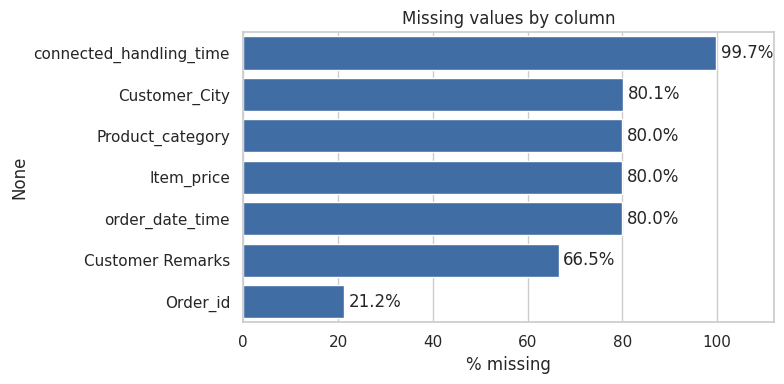

In [8]:
# Visualizing the missing values
m = (raw.isna().mean() * 100).sort_values(ascending=False)
m = m[m > 0]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=m.values, y=m.index, color=BLUE, ax=ax)
for i, v in enumerate(m.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 112); ax.set_xlabel("% missing"); ax.set_title("Missing values by column")
plt.tight_layout(); plt.show()

### What did you know about your dataset?

* **85,907 tickets x 20 columns**, one month of Shopzilla support interactions (reported 28 Jul - 31 Aug 2023, surveyed 1-31 Aug 2023). The target `CSAT Score` has **no missing values**.
* **No duplicate rows and `Unique id` is truly unique**, so no records had to be removed. `Order_id` repeats a little (several tickets about one order), which is legitimate.
* **Missingness is structural, not random.** `Order_id` is missing for ~21 % of tickets; `order_date_time`, `Item_price`, `Product_category` and `Customer_City` are missing for ~80 % - these are tickets *not linked to an order* (e.g. general queries). `connected_handling_time` is missing for 99.7 % (only 242 values) and is useless as a feature. `Customer Remarks` is missing for 67 % simply because most customers do not write a comment.
* The target is **highly imbalanced and J-shaped**: ~69 % of customers give 5, ~13 % give 4, ~13 % give 1, and the middle scores (2 and 3) are rare.
* Date columns are stored as **strings in two different formats** (`dd/mm/yyyy hh:mm` and `dd-Mon-yy`) and must be parsed.
* `issue_responded` is *earlier* than `Issue_reported at` in ~3,100 rows - a data-quality anomaly we must handle explicitly.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(raw.columns)

['Unique id',
 'channel_name',
 'category',
 'Sub-category',
 'Customer Remarks',
 'Order_id',
 'order_date_time',
 'Issue_reported at',
 'issue_responded',
 'Survey_response_Date',
 'Customer_City',
 'Product_category',
 'Item_price',
 'connected_handling_time',
 'Agent_name',
 'Supervisor',
 'Manager',
 'Tenure Bucket',
 'Agent Shift',
 'CSAT Score']

In [10]:
# Dataset Describe
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_name,85907,3,Inbound,68142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,85907,12,Returns,44097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-category,85907,57,Reverse Pickup Enquiry,22389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Remarks,28742,18231,Good,1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date_time,17214,13766,09/08/2023 11:55,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Issue_reported at,85907,30923,13/08/2023 10:40,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_responded,85907,30262,28/08/2023 00:00,3378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survey_response_Date,85907,31,28-Aug-23,3452,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

| Variable | Meaning | Type / note |
|---|---|---|
| Unique id | Ticket identifier | ID - not predictive, dropped |
| channel_name | Inbound call / Outcall / Email | categorical (3) |
| category, Sub-category | Issue type (12 / 57 levels) | categorical; Sub-category is long-tailed |
| Customer Remarks | Free-text comment written with the survey | text - **leakage risk**, excluded from the production model |
| Order_id | Order the ticket refers to | ID - only its presence is informative |
| order_date_time | When the order was placed | datetime, 80 % missing (non-order tickets) |
| Issue_reported at / issue_responded | When the customer raised the issue / support responded | datetime -> response time |
| Survey_response_Date | Day the survey was answered | datetime -> survey lag |
| Customer_City, Product_category, Item_price | Order context | mostly missing, informative when present |
| connected_handling_time | Call handling time | 99.7 % missing - dropped |
| Agent_name, Supervisor, Manager | Staff hierarchy (1,371 / 40 / 6) | high-cardinality categorical |
| Tenure Bucket, Agent Shift | Agent experience and shift | categorical |
| **CSAT Score** | **Target, 1-5** | ordinal integer, imbalanced |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
pd.DataFrame({"n_unique": raw.nunique(), "dtype": raw.dtypes.astype(str)}).sort_values("n_unique")

,n_unique,dtype
channel_name,3,str
CSAT Score,5,int64
Agent Shift,5,str
Tenure Bucket,5,str
Manager,6,str
Product_category,9,str
category,12,str
Survey_response_Date,31,str
Supervisor,40,str
Sub-category,57,str


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Feature construction used throughout the EDA (pure pandas; the same logic is reused by the ML notebook)
import numpy as np
import pandas as pd
CAT_COLS = ["channel_name", "category", "Sub-category", "Product_category",
            "Tenure Bucket", "Agent Shift", "Manager", "Supervisor", "Customer_City"]
NUM_COLS = ["response_min", "log_response_min", "resp_negative_flag", "rep_hour", "rep_dow",
            "rep_day", "is_weekend", "survey_lag_days", "has_order_info",
            "order_to_issue_days", "log_item_price", "has_order_id"]
AGENT_COL = "Agent_name"
RAW_INPUT_COLS = ["channel_name", "category", "Sub-category", "Customer Remarks", "Order_id",
                  "order_date_time", "Issue_reported at", "issue_responded", "Survey_response_Date",
                  "Customer_City", "Product_category", "Item_price", "Agent_name", "Supervisor",
                  "Manager", "Tenure Bucket", "Agent Shift"]


# --------------------------------------------------------------------------
# Feature engineering (row-level only -> safe for real-time scoring)
# --------------------------------------------------------------------------
def engineer(raw: pd.DataFrame) -> pd.DataFrame:
    """Turn raw ticket rows into model-ready features. No target information is used."""
    d = pd.DataFrame(index=raw.index)
    rep = pd.to_datetime(raw["Issue_reported at"], format="%d/%m/%Y %H:%M", errors="coerce")
    resp = pd.to_datetime(raw["issue_responded"], format="%d/%m/%Y %H:%M", errors="coerce")
    survey = pd.to_datetime(raw["Survey_response_Date"], format="%d-%b-%y", errors="coerce")
    order = pd.to_datetime(raw["order_date_time"], format="%d/%m/%Y %H:%M", errors="coerce")

    # Responsiveness: the single most important operational driver (see EDA).
    rt = (resp - rep).dt.total_seconds() / 60.0
    d["resp_negative_flag"] = (rt < 0).astype(int)          # data-entry anomaly (responded before reported)
    d["response_min"] = rt.clip(lower=0).fillna(0)
    d["log_response_min"] = np.log1p(d["response_min"])

    # Calendar features
    d["rep_hour"] = rep.dt.hour.fillna(12)
    d["rep_dow"] = rep.dt.dayofweek.fillna(0)
    d["rep_day"] = rep.dt.day.fillna(15)
    d["is_weekend"] = (d["rep_dow"] >= 5).astype(int)
    d["survey_lag_days"] = (survey - rep.dt.normalize()).dt.days.clip(-5, 31).fillna(0)

    # Order information (missing for ~80% of tickets = not order-linked)
    d["has_order_info"] = order.notna().astype(int)
    d["order_to_issue_days"] = ((rep - order).dt.total_seconds() / 86400).clip(0, 400).fillna(0)
    d["log_item_price"] = np.log1p(pd.to_numeric(raw["Item_price"], errors="coerce").fillna(0).clip(lower=0))
    d["has_order_id"] = raw["Order_id"].notna().astype(int)

    # Categoricals (missing -> explicit 'Unknown' level)
    for c in CAT_COLS:
        d[c] = raw[c].fillna("Unknown").astype(str).str.strip()
    d[AGENT_COL] = raw[AGENT_COL].fillna("Unknown").astype(str)
    return d

In [13]:
# Write your code to make your dataset analysis ready.
y = raw["CSAT Score"].astype(int).values            # target: 1..5
feat = engineer(raw)                                  # parsed dates, response time, calendar & order features, cleaned categoricals

eda = feat.copy()
eda["CSAT"] = y
eda["low"] = (eda["CSAT"] <= 2).astype(int)           # 'dissatisfied' flag used throughout the EDA
eda["reported_at"] = pd.to_datetime(raw["Issue_reported at"], format="%d/%m/%Y %H:%M")
eda["survey_date"] = pd.to_datetime(raw["Survey_response_Date"], format="%d-%b-%y")
eda["rt_bucket"] = pd.cut(eda["response_min"], [-1, 5, 15, 60, 240, 1440, 1e9],
                          labels=["0-5 min", "5-15 min", "15-60 min", "1-4 h", "4-24 h", ">24 h"])
print("Analysis frame:", eda.shape)
print("Responses logged before the issue was reported:", int(feat.resp_negative_flag.sum()),
      f"({feat.resp_negative_flag.mean():.1%}) -> clipped to 0 min and flagged")
print("Overall dissatisfaction rate (CSAT<=2): {:.1%}".format(eda.low.mean()))
feat.head(3).T

Analysis frame: (85907, 27)
Responses logged before the issue was reported: 3128 (3.6%) -> clipped to 0 min and flagged
Overall dissatisfaction rate (CSAT<=2): 14.6%


,0,1,2
resp_negative_flag,0,0,0
response_min,34.0,2.0,22.0
log_response_min,3.555348,1.098612,3.135494
rep_hour,11,12,20
rep_dow,1,1,1
rep_day,1,1,1
is_weekend,0,0,0
survey_lag_days,0,0,0
has_order_info,0,0,0
order_to_issue_days,0.0,0.0,0.0


### What all manipulations have you done and insights you found?

1. **Parsed all four timestamp columns** with their explicit formats (zero parse failures for the three always-present ones; `order_date_time` is legitimately empty for 80 % of rows).
2. **Response time** = `issue_responded - Issue_reported at` in minutes. 3,128 rows (3.6 %) are negative (response before report): physically impossible, so we **clip to 0 and add a `resp_negative_flag`** instead of dropping rows - the flag lets the model learn whether the anomaly carries information (it does not look dangerous: those tickets are mostly satisfied).
3. **Calendar features:** reported hour, weekday, day-of-month, weekend flag, and the **survey lag** (days between report and survey).
4. **Order context:** a flag for "ticket linked to an order", days between order and issue, `log1p(Item_price)`, flag for order id present. Missing numeric values become 0 *plus* an explicit flag, because "missing" means "not an order ticket" - that is information, not noise.
5. **Categorical gaps** become an explicit `Unknown` level.
6. **Dropped:** `Unique id`, `Order_id` (pure identifiers), `connected_handling_time` (99.7 % missing), the raw timestamps (replaced by derived features) and `Customer Remarks` (kept out of the numeric analysis; it is written together with the survey answer).
7. **No rows were removed**, so no information was lost.

**Key early insight:** the median response time is 5 minutes, but the long tail is huge (max ~4 days), and the dissatisfaction rate climbs from ~9 % for 0-5 min responses to ~36 % for responses slower than 24 h (Chart 8).

(Note: `Customer Remarks` is written by the customer at the same time as the score, so it is a consequence of satisfaction, not a driver; it is therefore not used as an explanatory variable here.)

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

Following the **UBM rule**: Charts 1-5 are *Univariate*, 6-15 are *Bivariate*, 16-19 are *Multivariate* (including the correlation heat-map and the pair plot) and Chart 20 is an extra bivariate view of issue sub-categories. "Dissatisfied" always means **CSAT <= 2** (14.6 % of tickets). A few helper functions keep the chart code short.

In [14]:
# Helpers used by the bivariate charts
GLOBAL_LOW = eda["low"].mean()

def rate_table(col, order=None):
    """Dissatisfaction rate, ticket count and 95% CI per level of `col`."""
    g = eda.groupby(col, observed=True)["low"].agg(["mean", "size"]).rename(columns={"mean": "rate", "size": "n"})
    g["ci"] = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
    return g.loc[order] if order is not None else g.sort_values("rate")

def rate_bar(col, order=None, horizontal=False, title="", figsize=(8, 4), min_n=0):
    g = rate_table(col, order)
    g = g[g.n >= min_n]
    fig, ax = plt.subplots(figsize=figsize)
    x = g["rate"] * 100; e = g["ci"] * 100
    if horizontal:
        ax.barh(g.index.astype(str), x, xerr=e, color=BLUE, capsize=3)
        ax.axvline(GLOBAL_LOW * 100, color=RED, ls="--", label=f"overall {GLOBAL_LOW:.1%}")
        for i, (v, n) in enumerate(zip(x, g.n)): ax.text(v + e.iloc[i] + .5, i, f"n={n:,}", va="center", fontsize=8)
        ax.set_xlabel("% dissatisfied (CSAT<=2)")
    else:
        ax.bar(g.index.astype(str), x, yerr=e, color=BLUE, capsize=3)
        ax.axhline(GLOBAL_LOW * 100, color=RED, ls="--", label=f"overall {GLOBAL_LOW:.1%}")
        for i, (v, n) in enumerate(zip(x, g.n)): ax.text(i, v + e.iloc[i] + .4, f"n={n:,}", ha="center", fontsize=8)
        ax.set_ylabel("% dissatisfied (CSAT<=2)")
    ax.set_title(title); ax.legend(); plt.tight_layout(); plt.show()
    return g

#### Chart - 1: Distribution of the target (CSAT Score)  [Univariate]

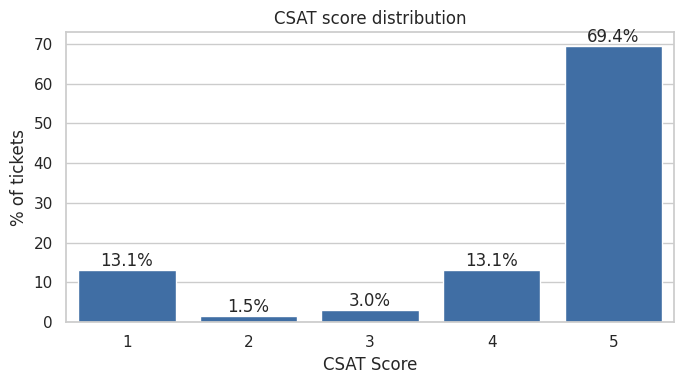

In [15]:
# Chart - 1 visualization code
s = eda["CSAT"].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=s.index, y=s.values, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_xlabel("CSAT Score"); ax.set_ylabel("% of tickets"); ax.set_title("CSAT score distribution")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the clearest way to show the shape of a small discrete, ordinal target. Knowing the class balance is the first thing to settle before choosing a loss function and metrics.

##### 2. What is/are the insight(s) found from the chart?

The distribution is **J-shaped and strongly imbalanced**: 69.4 % of tickets score 5, 13.1 % score 4, 13.1 % score 1, and only 1.5 % / 3.0 % score 2 / 3. Customers are polarised - they are either delighted or very angry, with few lukewarm answers. A naive 'always predict 5' model would be 69.4 % accurate while being useless.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the business is healthy overall (mean CSAT ~4.2) and the 'very unhappy' group (score 1, 13 %) is a well-defined, actionable target for service recovery. **Negative / risk:** 1-star customers outnumber 2-3-star customers 3-to-1, which means dissatisfaction is expressed as outright failure rather than mild annoyance - these customers are the likeliest to churn. It also tells us **accuracy is the wrong metric**; we use macro-F1, quadratic kappa and AUC of the 'dissatisfied' detector, and class-weighted training.

#### Chart - 2: Ticket volume by support channel  [Univariate]

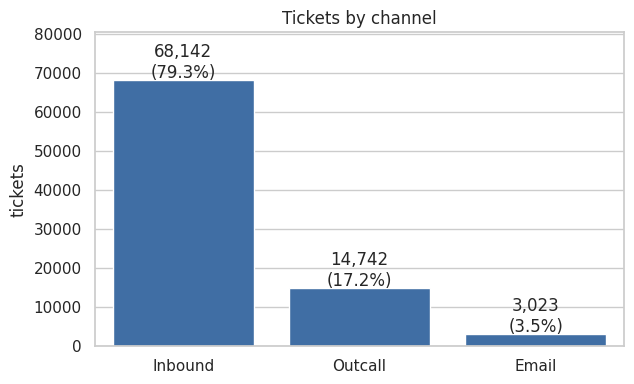

In [16]:
# Chart - 2 visualization code
s = eda["channel_name"].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.barplot(x=s.index, y=s.values, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(i, v + 600, f"{v:,}\n({v / s.sum():.1%})", ha="center")
ax.set_ylim(0, s.max() * 1.18); ax.set_ylabel("tickets"); ax.set_xlabel("")
ax.set_title("Tickets by channel"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Channel has only three levels, so a simple labelled bar chart shows both absolute volume and share at a glance.

##### 2. What is/are the insight(s) found from the chart?

**Inbound calls dominate (79.3 %)**, outbound calls are 17.2 % and e-mail is only 3.5 % (3,023 tickets). Even the smallest channel has thousands of tickets, so channel comparisons later are statistically meaningful.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the load is concentrated on the phone channel, so improvements in call handling pay off at scale. **Negative:** because e-mail is so small it is easily ignored in operations - Chart 6 shows that is exactly where satisfaction is weakest, so a neglected small channel can quietly hurt the brand.

#### Chart - 3: Ticket volume by issue category  [Univariate]

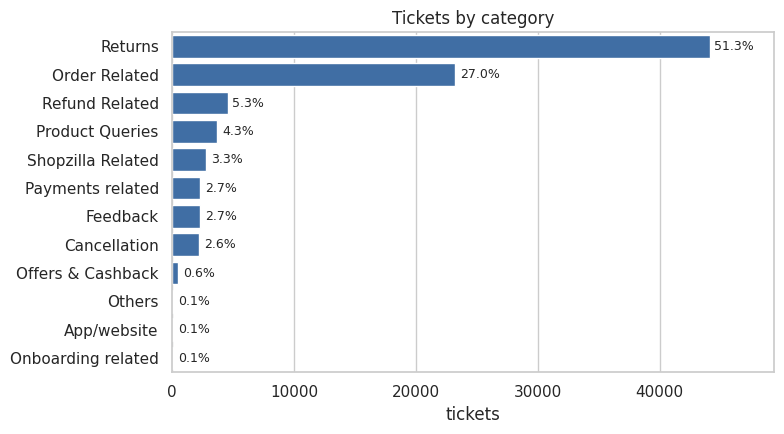

In [17]:
# Chart - 3 visualization code
s = eda["category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=s.values, y=s.index, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(v + 400, i, f"{v / s.sum():.1%}", va="center", fontsize=9)
ax.set_xlim(0, s.max() * 1.12); ax.set_xlabel("tickets"); ax.set_ylabel("")
ax.set_title("Tickets by category"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A sorted horizontal bar chart handles 12 long category names much better than a column chart or a pie and exposes the long tail immediately.

##### 2. What is/are the insight(s) found from the chart?

**Returns (51.3 %) and Order Related (27.0 %) account for ~78 % of all tickets.** Eight categories each have under 5 % of the volume and four (App/website, Onboarding, Others, Offers) have fewer than 500 tickets in the whole month.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a handful of categories drive the workload, so process fixes there (e.g. self-service returns tracking) reduce cost and wait times at scale. **Negative:** tiny categories have very noisy statistics - any 'insight' about them (e.g. the 33 % dissatisfaction in 'Others', n=99) must be read with caution, which is why later charts print the sample size and confidence intervals.

#### Chart - 4: Distribution of response time  [Univariate]

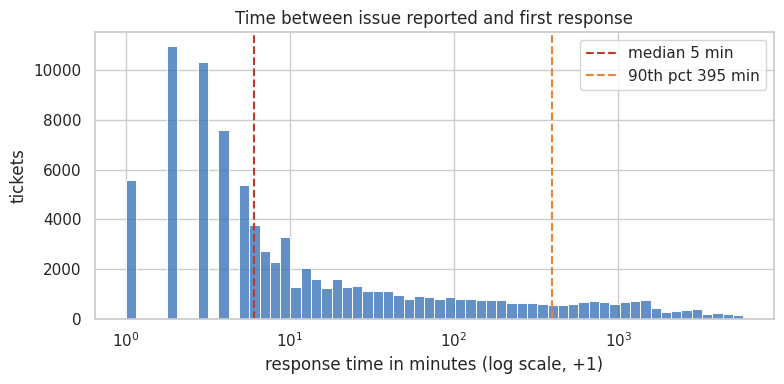

count    85907.0
mean       169.7
std        555.8
min          0.0
50%          5.0
75%         35.0
90%        395.0
95%       1079.0
99%       3007.0
max       5758.0
Name: response_min, dtype: float64


In [18]:
# Chart - 4 visualization code
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(eda["response_min"] + 1, log_scale=True, bins=60, color=BLUE, ax=ax)
med = eda["response_min"].median(); p90 = eda["response_min"].quantile(.9)
ax.axvline(med + 1, color=RED, ls="--", label=f"median {med:.0f} min")
ax.axvline(p90 + 1, color=ORANGE, ls="--", label=f"90th pct {p90:.0f} min")
ax.set_xlabel("response time in minutes (log scale, +1)"); ax.set_ylabel("tickets")
ax.set_title("Time between issue reported and first response"); ax.legend(); plt.tight_layout(); plt.show()
print(eda["response_min"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

##### 1. Why did you pick the specific chart?

Response time spans four orders of magnitude (0 minutes to ~4 days), so a histogram on a **log axis** is needed to see the body and the tail of the distribution together; on a linear axis everything would collapse into one bar.

##### 2. What is/are the insight(s) found from the chart?

The distribution is extremely right-skewed: **median = 5 min**, but the 75th percentile is 35 min and the tail runs beyond 24 hours. There are two groups: a fast cluster of 0-10 minute responses (mostly calls) and a long tail of slow, probably e-mail or back-office resolved cases.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most customers are answered fast, which supports the high CSAT. **Negative:** the long tail is where the unhappy customers live (see Charts 8 and 15). The skewness also tells us that **summary statistics must use medians/percentiles or a log scale**, because a few extreme values dominate the mean.

#### Chart - 5: Ticket volume by hour of day  [Univariate]

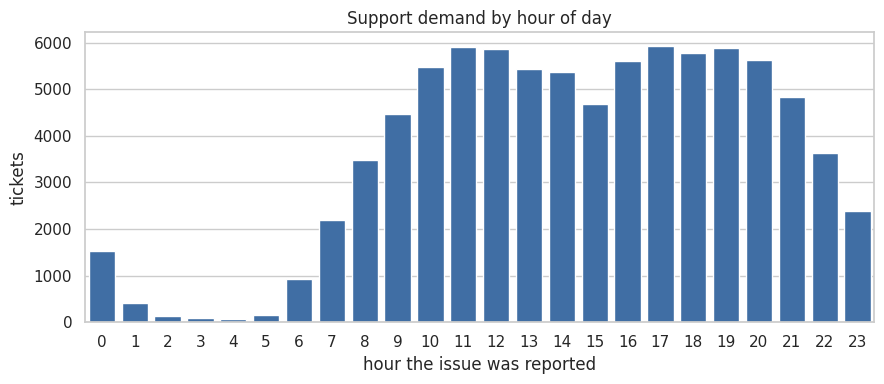

Share of tickets reported 09:00-21:59: 82.5%


In [19]:
# Chart - 5 visualization code
s = eda["rep_hour"].astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=s.index, y=s.values, color=BLUE, ax=ax)
ax.set_xlabel("hour the issue was reported"); ax.set_ylabel("tickets"); ax.set_title("Support demand by hour of day")
plt.tight_layout(); plt.show()
print("Share of tickets reported 09:00-21:59: {:.1%}".format(s.loc[9:21].sum() / s.sum()))

##### 1. Why did you pick the specific chart?

Hour of day is a cyclic, discrete variable; a bar chart per hour shows the daily demand profile and any gaps in coverage.

##### 2. What is/are the insight(s) found from the chart?

Demand is **business-hours driven**: it ramps up from 06:00, plateaus at roughly 4,700-5,900 tickets per hour between 10:00 and 21:00 and falls off after 22:00 (3,633 at 22:00, 2,398 at 23:00); between 01:00 and 05:00 there are fewer than 450 tickets per hour. About 82.5 % of tickets arrive between 09:00 and 21:59.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a predictable flat 10:00-21:00 plateau makes staffing easy to plan, and the near-empty night hours show night staffing can be minimal. **Negative:** the plateau is *flat*, not peaked - there is no obvious quiet period in which to schedule training, so coaching time has to be planned deliberately.

#### Chart - 6: CSAT mix by channel  [Bivariate: categorical vs categorical]

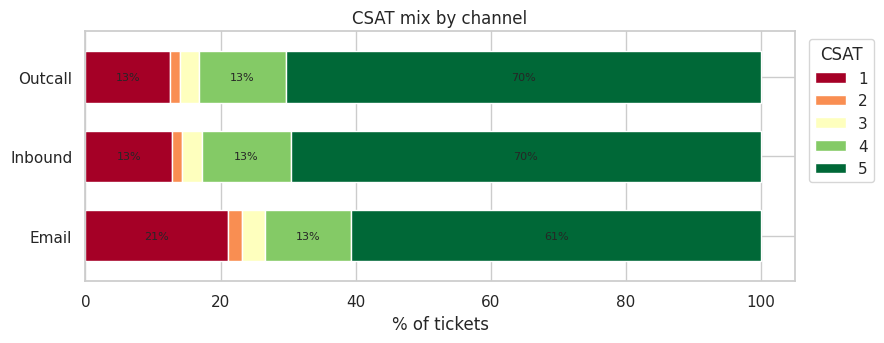

               mean   size
channel_name              
Email         3.899   3023
Inbound       4.251  68142
Outcall       4.270  14742
               rate      n     ci
channel_name                     
Outcall       0.140  14742  0.006
Inbound       0.143  68142  0.003
Email         0.232   3023  0.015


In [20]:
# Chart - 6 visualization code
ct = pd.crosstab(eda["channel_name"], eda["CSAT"], normalize="index") * 100
ct = ct.loc[["Email", "Inbound", "Outcall"]]
ax = ct.plot(kind="barh", stacked=True, figsize=(9, 3.6), colormap="RdYlGn", width=.65)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in c], label_type="center", fontsize=8)
ax.set_xlabel("% of tickets"); ax.set_ylabel(""); ax.set_title("CSAT mix by channel"); ax.legend(title="CSAT", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
print(eda.groupby("channel_name")["CSAT"].agg(["mean", "size"]).round(3))
print(rate_table("channel_name").round(3))

##### 1. Why did you pick the specific chart?

A 100 % stacked bar shows the *whole* score mix per channel, which a single average would hide - important here because the target is polarised.

##### 2. What is/are the insight(s) found from the chart?

**E-mail is clearly worse: mean CSAT 3.90 versus 4.25 (Inbound) and 4.27 (Outcall), and 23.2 % of e-mail customers are dissatisfied versus ~14 % on the phone channels.** Inbound and Outcall are almost identical.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** there is a concrete, low-volume fix - improving e-mail response quality/time lifts a whole channel. Phone channels are performing consistently. **Negative:** e-mail's 23 % dissatisfaction is ~1.6x the phone rate; if the business pushes customers to e-mail to deflect call volume, overall satisfaction will fall.

#### Chart - 7: Dissatisfaction rate by issue category  [Bivariate]

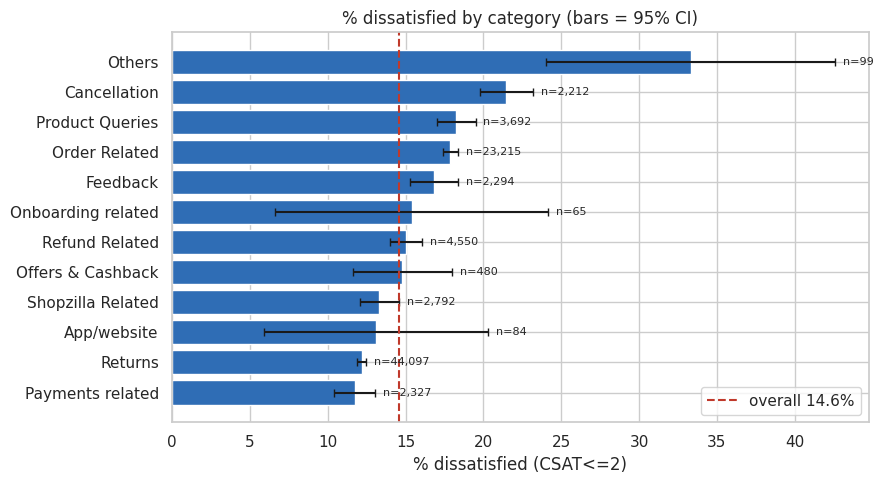

In [21]:
# Chart - 7 visualization code
g = rate_bar("category", horizontal=True, title="% dissatisfied by category (bars = 95% CI)", figsize=(9, 5))

##### 1. Why did you pick the specific chart?

A sorted horizontal bar of *rates* (not counts) with confidence intervals and sample sizes separates real differences from small-sample noise.

##### 2. What is/are the insight(s) found from the chart?

The worst categories are **Others (33 %, n=99), Cancellation (21.5 %, n=2,212), Product Queries (18.3 %) and Order Related (17.9 %)**; the best are **Payments (11.7 %) and Returns (12.2 %)**, even though Returns is the largest category. Only differences between large categories (Cancellation / Order / Product vs Returns / Payments) are statistically solid; 'Others', 'App/website' and 'Onboarding' have wide intervals.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the largest category (Returns, 51 % of volume) is also among the happiest - a good sign for the core process. Cancellation and Order Related are clear targets for training and process redesign. **Negative:** Order Related is large (23k tickets) *and* above average in dissatisfaction, so it contributes the biggest absolute number of unhappy customers; ignoring it would leave most of the problem untouched.

#### Chart - 8: Response-time bucket vs dissatisfaction  [Bivariate: numeric (binned) vs target]

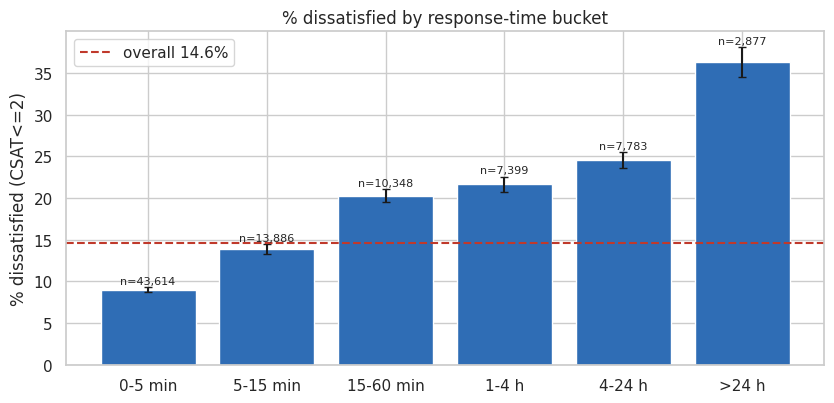

            rate      n     ci
rt_bucket                     
0-5 min    0.090  43614  0.003
5-15 min   0.139  13886  0.006
15-60 min  0.203  10348  0.008
1-4 h      0.216   7399  0.009
4-24 h     0.246   7783  0.010
>24 h      0.363   2877  0.018


In [22]:
# Chart - 8 visualization code
g = rate_bar("rt_bucket", order=["0-5 min", "5-15 min", "15-60 min", "1-4 h", "4-24 h", ">24 h"],
             title="% dissatisfied by response-time bucket", figsize=(8.5, 4.2))
print(g.round(3))

##### 1. Why did you pick the specific chart?

Binning the continuous response time into SLA-style buckets turns a skewed numeric variable into an easy-to-read dose-response chart, and error bars show the statistical certainty for each bucket.

##### 2. What is/are the insight(s) found from the chart?

A **monotonic dose-response**: dissatisfaction rises from **8.9 % (answered within 5 min) to 13.9 % (5-15 min), 20.3 % (15-60 min), 21.6 % (1-4 h), 24.6 % (4-24 h) and 36.3 % when the wait exceeds 24 hours.** Customers who wait over a day are 4x as likely to be unhappy as those answered within 5 minutes.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Strongly positive:** this is the clearest *actionable* lever in the dataset. A first-response SLA (e.g. 15 minutes) targets the point where the dissatisfaction curve starts to climb steeply. **Negative:** if slow tickets are not escalated, each extra hour in the queue costs satisfaction. The mild caveat is causality - complex issues are both slower and more upsetting - but the gradient is far too large to be ignored. This is the single most important feature for the ANN.

#### Chart - 9: Dissatisfaction by agent tenure  [Bivariate]

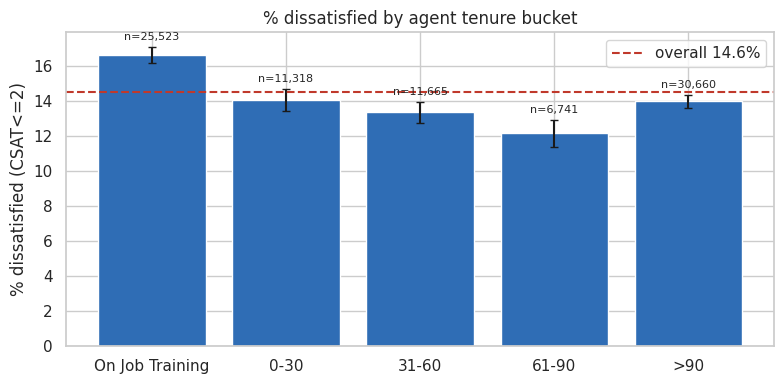

In [23]:
# Chart - 9 visualization code
g = rate_bar("Tenure Bucket", order=["On Job Training", "0-30", "31-60", "61-90", ">90"],
             title="% dissatisfied by agent tenure bucket", figsize=(8, 4))

##### 1. Why did you pick the specific chart?

Tenure is an ordered category, so I kept its natural order and used a rate bar with confidence intervals to see whether experience matters.

##### 2. What is/are the insight(s) found from the chart?

Agents **on job training have the highest dissatisfaction (16.6 %)**, while the 31-60 and 61-90 day cohorts are best (13.4 % and 12.2 %). Interestingly the >90-day group (14.0 %) is not better than the 0-30 day group (14.1 %), so the relationship is not simply 'more experience = better'.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the training cohort is a clear, targetable group - pairing trainees with mentors or routing hard categories (Cancellation, Order Related) away from them is cheap. **Negative:** the training cohort handles 25.5k tickets (30 % of all volume), so the 2-4 pt penalty adds up to hundreds of avoidable unhappy customers every month. The lack of improvement after 90 days suggests a plateau where ongoing coaching is missing.

#### Chart - 10: Dissatisfaction by agent shift  [Bivariate]

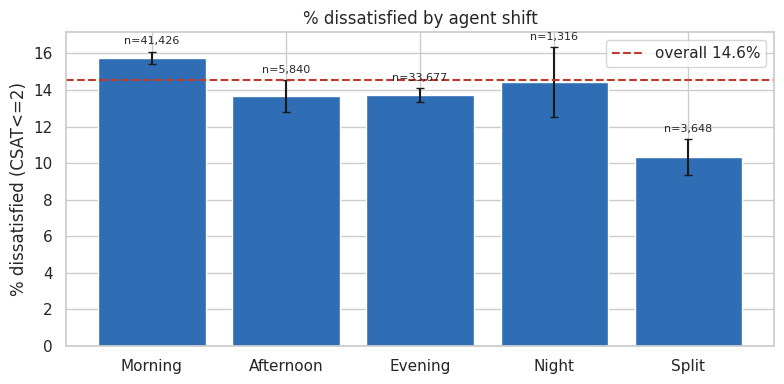

In [24]:
# Chart - 10 visualization code
g = rate_bar("Agent Shift", order=["Morning", "Afternoon", "Evening", "Night", "Split"],
             title="% dissatisfied by agent shift", figsize=(8, 4))

##### 1. Why did you pick the specific chart?

Same rate-bar design as Charts 7-9 so the effect sizes are directly comparable across variables.

##### 2. What is/are the insight(s) found from the chart?

**Morning shift is the weakest (15.8 %)** and the **Split shift the strongest (10.3 %)**; Afternoon, Evening and Night sit around 13.7-14.4 %. Morning handles the most tickets (41k), so its penalty is not a small-sample artefact.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the Split-shift practices (maybe different staffing mix or ticket types) could be studied and copied. **Negative:** Morning handles ~48 % of all tickets with the highest dissatisfaction, so it deserves attention in rostering (it likely also combines many trainee agents, a confounder worth testing in Chart 18).

#### Chart - 11: Dissatisfaction by product category  [Bivariate]

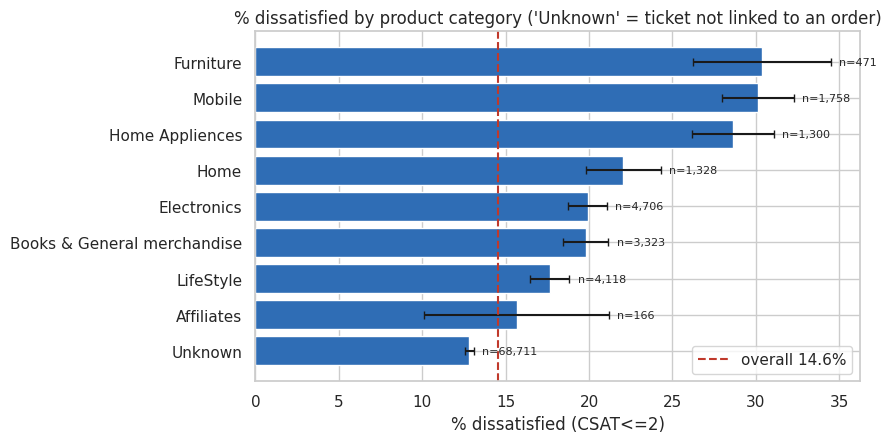

In [25]:
# Chart - 11 visualization code
g = rate_bar("Product_category", horizontal=True, min_n=100,
             title="% dissatisfied by product category ('Unknown' = ticket not linked to an order)", figsize=(9, 4.6))

##### 1. Why did you pick the specific chart?

Product category has nine levels with a very large 'Unknown' group; a rate bar with sample sizes makes comparison fair across very different volumes.

##### 2. What is/are the insight(s) found from the chart?

**Order-linked tickets are far less happy than non-order tickets: Unknown/no-order 12.8 % vs 21.5 % for order-linked tickets.** Within products, **Furniture (30 %), Mobile (30 %) and Home Appliances (29 %)** are the worst - all items that are bulky, expensive or need installation - whereas LifeStyle (17.7 %) and Books/General merchandise (19.8 %) are best.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** this is a strong separating variable (even *having* an order is informative), and the business can create specialised handling (installation scheduling, damage-in-transit protocols) for Furniture/Mobile/Appliances. **Negative:** high-value categories are the ones with the most dissatisfaction; those customers likely spend more, so each lost customer costs more.

#### Chart - 12: Item price vs CSAT  [Bivariate: numeric vs categorical]

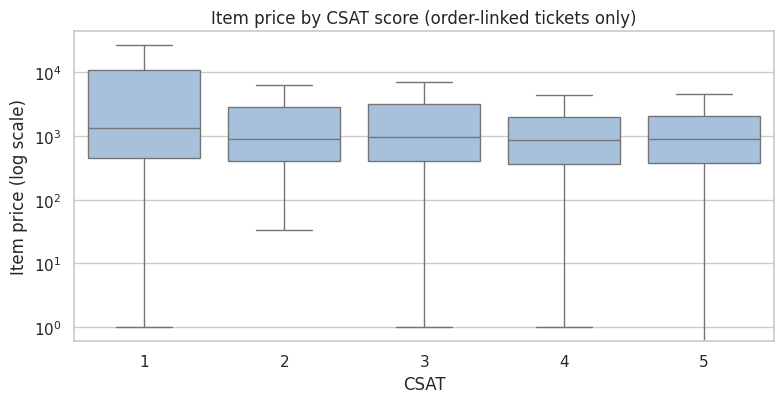

CSAT
1    1351.0
2     890.0
3     977.0
4     874.0
5     899.0
Name: Item_price, dtype: float64


In [26]:
# Chart - 12 visualization code
d = eda[raw["Item_price"].notna().values].copy()
d["Item_price"] = raw.loc[d.index, "Item_price"]
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=d, x="CSAT", y="Item_price", color="#9ec1e6", showfliers=False, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Item price (log scale)"); ax.set_title("Item price by CSAT score (order-linked tickets only)")
plt.tight_layout(); plt.show()
print(d.groupby("CSAT")["Item_price"].median().round(0))

##### 1. Why did you pick the specific chart?

A box plot on a log axis is the standard way to compare a heavily skewed numeric variable (prices range from 0 to 165,000) across the five ordered score groups.

##### 2. What is/are the insight(s) found from the chart?

**Dissatisfied customers bought pricier items:** the median item price of 1-star tickets is 1,351 versus 874-977 for every other score, and the boxes for scores 2-5 overlap almost completely. So price matters mainly at the extreme: it is the 1-star group, not the 2-3 star group, that stands out.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a high-value-order flag (e.g. top price tier) is a cheap trigger for proactive outreach and priority routing, because those customers are both likelier to be angry and worth more. **Negative:** the relationship is not monotonic across 2-5, so price alone is a weak explanation; it must be read together with product category and response time.

#### Chart - 13: Daily trend of customer satisfaction  [Bivariate: time series]

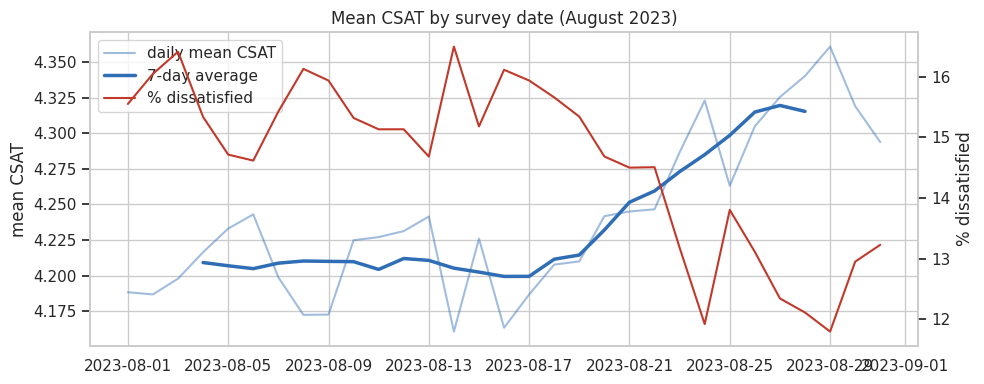

{'mean_csat': 4.209, 'low': 0.154} <- first week
{'mean_csat': 4.315, 'low': 0.128} <- last week


In [27]:
# Chart - 13 visualization code
daily = eda.groupby("survey_date").agg(mean_csat=("CSAT", "mean"), low=("low", "mean"), n=("CSAT", "size"))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily["mean_csat"], color=BLUE, alpha=.45, label="daily mean CSAT")
ax.plot(daily.index, daily["mean_csat"].rolling(7, center=True).mean(), color=BLUE, lw=2.5, label="7-day average")
ax.set_ylabel("mean CSAT"); ax.set_title("Mean CSAT by survey date (August 2023)")
ax2 = ax.twinx(); ax2.plot(daily.index, daily["low"] * 100, color=RED, lw=1.5, label="% dissatisfied"); ax2.set_ylabel("% dissatisfied"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()
print(daily.iloc[:7][["mean_csat", "low"]].mean().round(3).to_dict(), "<- first week")
print(daily.iloc[-7:][["mean_csat", "low"]].mean().round(3).to_dict(), "<- last week")

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for a time series, and the rolling average strips out day-to-day noise so the underlying trend is visible. Dissatisfaction is overlaid on a second axis.

##### 2. What is/are the insight(s) found from the chart?

Satisfaction **improves steadily across the month**: the first week averages ~4.21 with ~15.4 % dissatisfied, the last week ~4.32 with ~12.8 % dissatisfied; the step-up starts around 22-23 August. Within the month there is no weekly seasonality worth speaking of.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a real, sustained improvement - worth finding out what changed around 22 Aug (staffing, SLA, a policy) and keeping it. **Caution:** the data show a time drift, so conclusions drawn from one month may not hold next month; with only one month of data, trends should be re-checked on more months before being treated as permanent.

#### Chart - 14: Dissatisfaction by manager  [Bivariate]

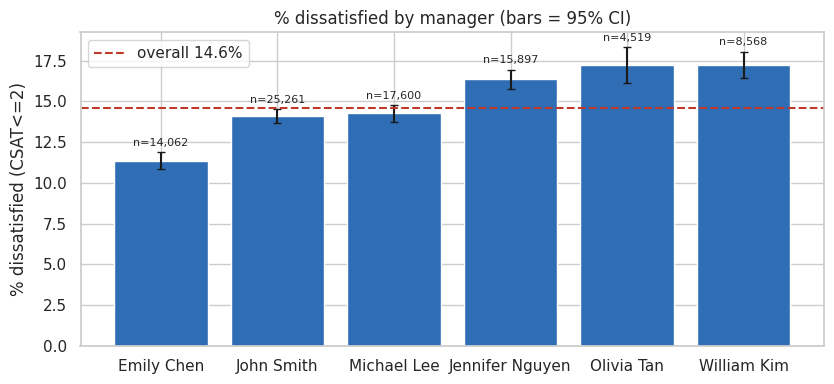

In [28]:
# Chart - 14 visualization code
g = rate_bar("Manager", title="% dissatisfied by manager (bars = 95% CI)", figsize=(8.5, 4))

##### 1. Why did you pick the specific chart?

Only six managers exist, so a rate bar with confidence intervals is enough to see whether team-level differences are real.

##### 2. What is/are the insight(s) found from the chart?

Dissatisfaction ranges from **11.3 % (Emily Chen) to 17.2 % (William Kim, Olivia Tan)** - a 6-point spread, and the confidence intervals do not overlap between the extremes. Teams under John Smith and Michael Lee sit at the overall average (~14 %).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** best-practice sharing - what does Emily Chen's team do differently? **Negative / caution:** this is a *team-level* comparison; teams handle different category/product mixes, so before using it for performance reviews it must be adjusted for ticket mix (the model's agent/manager features do implicitly). Using raw rankings for evaluation could be unfair.

#### Chart - 15: Do agents really differ? Observed spread vs pure chance  [Bivariate / Univariate]

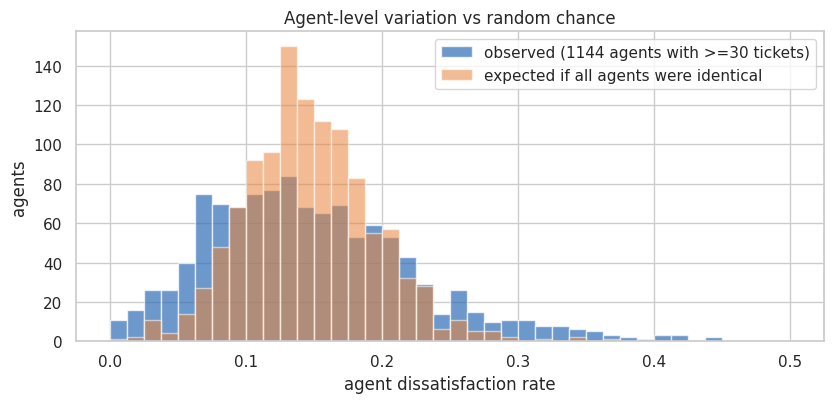

std observed = 0.088  vs  std expected by chance = 0.047


In [29]:
# Chart - 15 visualization code
ag = eda.groupby(raw["Agent_name"]).agg(n=("low", "size"), rate=("low", "mean"))
ag = ag[ag.n >= 30]
rng = np.random.default_rng(SEED)
simulated = rng.binomial(ag["n"].values, GLOBAL_LOW) / ag["n"].values      # what we'd see if all agents were identical
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bins = np.linspace(0, .5, 41)
ax.hist(ag["rate"], bins=bins, alpha=.7, color=BLUE, label=f"observed ({len(ag)} agents with >=30 tickets)")
ax.hist(simulated, bins=bins, alpha=.55, color=ORANGE, label="expected if all agents were identical")
ax.set_xlabel("agent dissatisfaction rate"); ax.set_ylabel("agents"); ax.set_title("Agent-level variation vs random chance")
ax.legend(); plt.tight_layout(); plt.show()
print(f"std observed = {ag['rate'].std():.3f}  vs  std expected by chance = {simulated.std():.3f}")

##### 1. Why did you pick the specific chart?

With 1,371 agents (too many to plot individually) the question is whether agent identity carries real signal. Overlaying the observed histogram on a simulation of 'all agents are identical' answers that directly and is a built-in significance check.

##### 2. What is/are the insight(s) found from the chart?

The observed distribution is **clearly wider than chance alone would produce**: standard deviation ~8.8 percentage points vs ~4.7 expected by chance (the printed output confirms both). Some agents have dissatisfaction rates above 30 % and others near 0 %, which cannot be explained by sampling noise.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** agent identity is a genuine predictor, so agent identity should not be ignored in any further analysis. Operationally, coaching the high-dissatisfaction tail would shift the whole distribution. **Negative:** the same feature makes the model less useful for brand-new agents (cold start) - for them the encoder falls back to the global average.

#### Chart - 16: Channel x category dissatisfaction heat-map  [Multivariate]

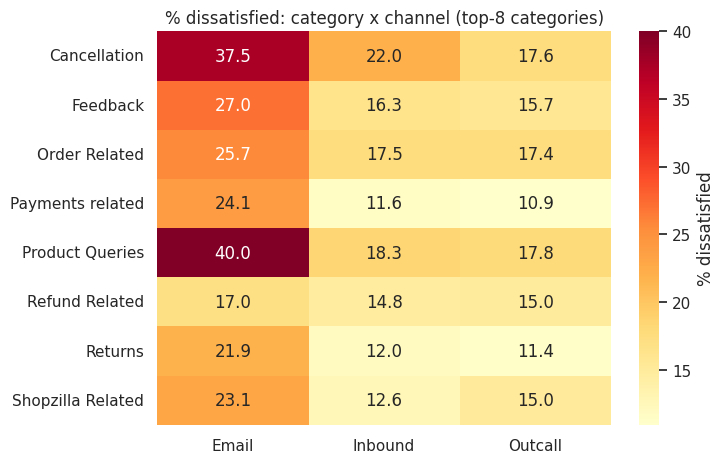

Smallest cell size: 10


In [30]:
# Chart - 16 visualization code
top = eda["category"].value_counts().index[:8]
d = eda[eda["category"].isin(top)]
pv = d.pivot_table(index="category", columns="channel_name", values="low", aggfunc="mean") * 100
cnt = d.pivot_table(index="category", columns="channel_name", values="low", aggfunc="size")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% dissatisfied"}, ax=ax)
ax.set_title("% dissatisfied: category x channel (top-8 categories)"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print("Smallest cell size:", int(cnt.min().min()))

##### 1. Why did you pick the specific chart?

A heat-map handles a two-dimensional categorical interaction (8 x 3 = 24 cells) in one picture and highlights hot spots with colour.

##### 2. What is/are the insight(s) found from the chart?

The e-mail penalty is **not uniform**. The most reliable cell is **Returns by e-mail: 21.9 % dissatisfied (n=1,213) vs 11-12 % by phone**; Payments shows 24 % by e-mail vs ~11 % by phone, and Order Related 25.7 % vs ~17.5 %. Cancellation by e-mail looks worst (37.5 %) but that cell has only 64 tickets, so treat it as a warning sign rather than a fact. Interestingly, Outcall beats Inbound for Cancellation (17.6 % vs 22.0 %), while Offers & Cashback is the reverse (23.3 % Outcall vs 13.6 % Inbound, small n).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it points to specific combinations to fix (e-mail returns and payments handling; inbound cancellation scripts) instead of blanket changes. **Negative / analytical implication:** the effect of channel depends on category, i.e. there is an **interaction** - such interactions cannot be seen in single-variable summaries and need although

#### Chart - 17: Correlation heat-map of engineered numeric features  [Multivariate]

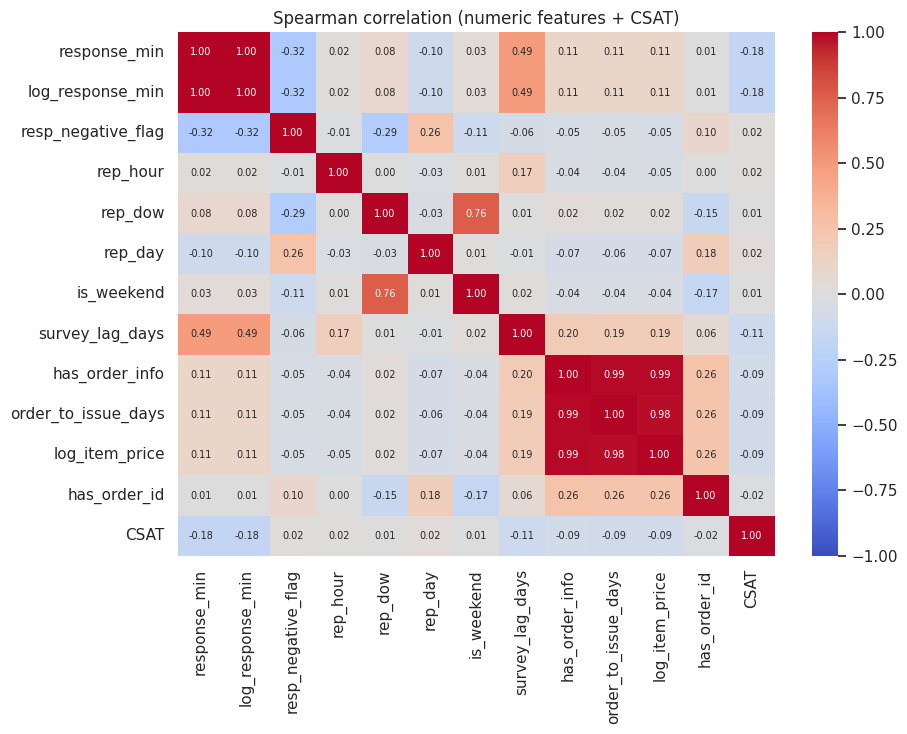

response_min          -0.178
log_response_min      -0.178
survey_lag_days       -0.112
log_item_price        -0.091
order_to_issue_days   -0.089
has_order_info        -0.086
has_order_id          -0.021
is_weekend             0.007
rep_dow                0.007
rep_hour               0.015
resp_negative_flag     0.016
rep_day                0.024
Name: CSAT, dtype: float64


In [31]:
# Chart - 17 visualization code
num = feat[NUM_COLS].copy(); num["CSAT"] = y
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation (numeric features + CSAT)")
plt.tight_layout(); plt.show()
print(corr["CSAT"].drop("CSAT").sort_values().round(3))

##### 1. Why did you pick the specific chart?

A correlation matrix is the standard multivariate check for multicollinearity and for a first ranking of numeric predictors. Spearman is used because the response time and price are skewed and the target is ordinal.

##### 2. What is/are the insight(s) found from the chart?

All correlations with CSAT are small: **response time is the strongest (Spearman -0.18)**, followed by survey lag (-0.11), item price (-0.09), order-to-issue days (-0.09) and the has-order flag (-0.09). Calendar features (hour, weekday, weekend, day-of-month) are essentially zero (|rho| < 0.03). The response-time pair (raw and log) are identical in rank terms, as expected, and survey lag / order flags correlate with each other, so the numeric block has some redundancy but nothing extreme.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms what the earlier charts suggested: response time is the number-one operational lever, and a longer wait before the survey goes with lower scores (customers whose issue dragged on rate lower). **Negative / analytical implication:** no single numeric feature explains more than ~3% of the rank variance (rho^2), so no single numeric variable explains much on its own; the explanatory power comes from combining them with categorical context. Calendar features carry almost no signal and are kept only because they are harmless. Spearman measures monotonic association only, so it can miss non-linear effects.

#### Chart - 18: Agent shift x tenure dissatisfaction heat-map  [Multivariate]

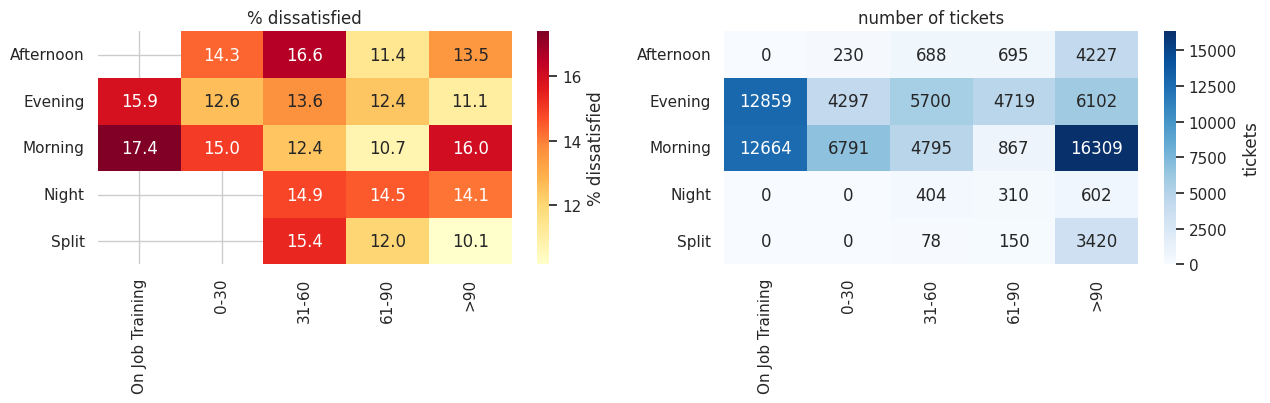

In [32]:
# Chart - 18 visualization code
pv = eda.pivot_table(index="Agent Shift", columns="Tenure Bucket", values="low", aggfunc="mean")[["On Job Training", "0-30", "31-60", "61-90", ">90"]] * 100
cnt = eda.pivot_table(index="Agent Shift", columns="Tenure Bucket", values="low", aggfunc="size")[["On Job Training", "0-30", "31-60", "61-90", ">90"]].fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "% dissatisfied"}); axes[0].set_title("% dissatisfied")
sns.heatmap(cnt, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar_kws={"label": "tickets"}); axes[1].set_title("number of tickets")
for a in axes: a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Charts 9 and 10 each looked at one agent attribute; a paired heat-map (rate + sample size) tests whether the shift effect is really a tenure effect in disguise (a confounder) and shows which cells are too small to trust.

##### 2. What is/are the insight(s) found from the chart?

On-job-training agents exist **only in the Morning and Evening shifts** (about 12.7k and 12.9k tickets). Within Morning, even experienced agents (>90 days) have a high 16.0 % dissatisfaction, versus 11.1 % for experienced Evening agents, so Morning's weakness is **not** just a tenure effect. The Split shift's 10.1 % is partly composition: 94 % of its tickets are handled by >90-day agents. The cells with the worst rates are Morning/OJT (17.4 %) and Morning/>90 (16.0 %).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows where to act - Morning-shift quality (regardless of tenure) and trainees in both shifts - rather than a blanket 'train everyone'. Some cells are empty or tiny (Night has no trainees, Split only 78 31-60 day tickets), so only large cells should drive decisions. **Negative / analytical implication:** shift, tenure and agent identity overlap strongly (confounding), so a single feature should not be read in isolation, and decisions should consider the combined cells.

### Summary of the EDA

| Driver | Strength | Evidence |
|---|---|---|
| **Response time** | Very strong | 8.9 % -> 36.3 % dissatisfied from <5 min to >24 h |
| **Order-linked / product category** | Strong | 12.8 % (no order) vs 21.5 %; Furniture/Mobile/Appliances ~30 % |
| **Channel (e-mail)** | Strong, small volume | 23.2 % vs ~14 % |
| **Issue category** | Moderate | Cancellation 21.5 % vs Payments 11.7 % |
| **Agent / manager / tenure / shift** | Moderate | Agent spread 2x wider than chance; OJT 16.6 % |
| **Time of day / weekday** | Weak | Flat 14-15 % across weekdays and most hours |

The dependence is mostly **non-linear and interaction-heavy** (channel x category, tenure x shift), and a large part of dissatisfaction is simply *not predictable from the ticket's metadata* (e.g. product quality, delivery). We therefore expect a **moderate ceiling** on predictive power - important for setting honest expectations.

#### Chart - 19: Pair plot of the continuous drivers, coloured by satisfaction  [Multivariate]

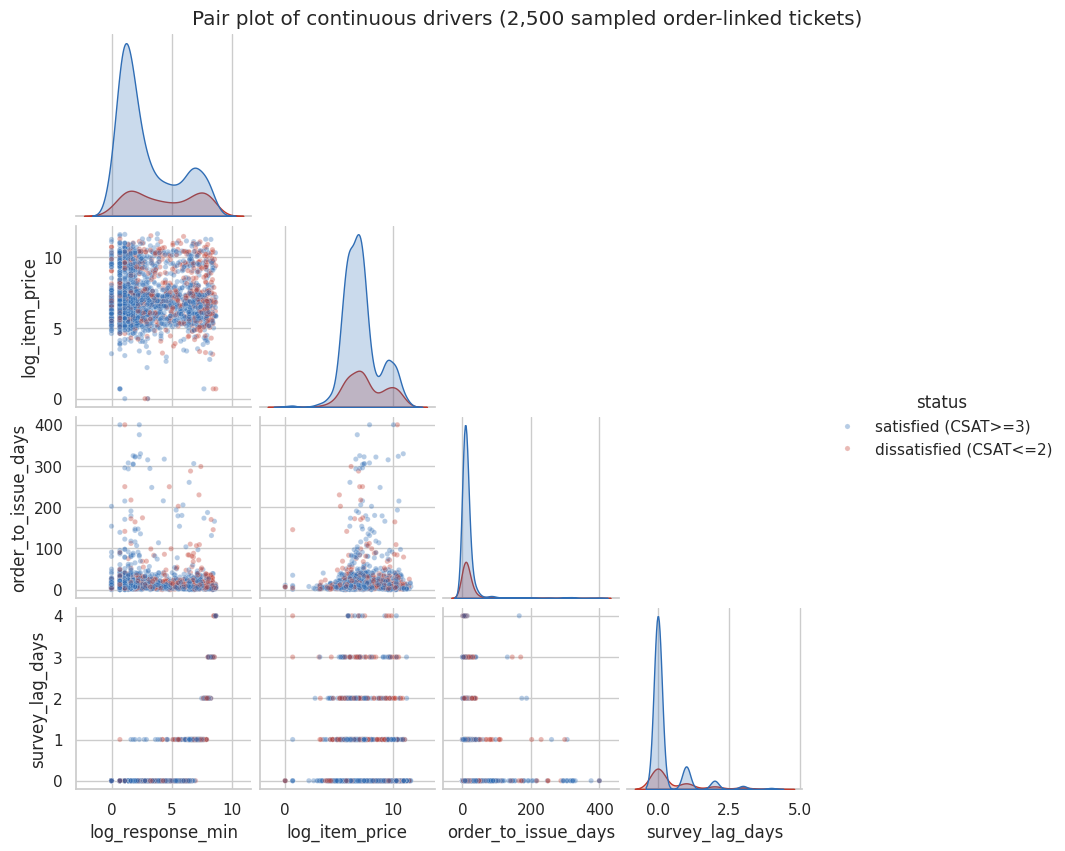

              log_response_min  log_item_price  order_to_issue_days  \
low                                                                   
satisfied                 1.95            6.80                 8.82   
dissatisfied              4.04            7.17                10.56   

              survey_lag_days  
low                            
satisfied                 0.0  
dissatisfied              0.0  


In [33]:
# Chart - 19 visualization code
d = feat[feat["has_order_info"] == 1].copy()                         # order-linked tickets only (otherwise order fields are all zero)
d["status"] = np.where(y[d.index] <= 2, "dissatisfied (CSAT<=2)", "satisfied (CSAT>=3)")
d = d.sample(2500, random_state=SEED)
cols = ["log_response_min", "log_item_price", "order_to_issue_days", "survey_lag_days"]
g = sns.pairplot(d, vars=cols, hue="status", palette={"dissatisfied (CSAT<=2)": RED, "satisfied (CSAT>=3)": BLUE},
                 corner=True, plot_kws={"alpha": .35, "s": 14}, diag_kind="kde", height=2.1)
g.fig.suptitle("Pair plot of continuous drivers (2,500 sampled order-linked tickets)", y=1.01)
plt.show()
full = feat[feat["has_order_info"] == 1].assign(low=(y[feat["has_order_info"].values == 1] <= 2))
print(full.groupby("low")[cols].median().round(2).rename(index={False: "satisfied", True: "dissatisfied"}))

##### 1. Why did you pick the specific chart?

A pair plot shows all pairwise relationships between the continuous variables at once and, with colour, whether the two satisfaction groups separate in any of them. It is the standard multivariate check for overlapping versus separable groups, and a sample keeps it readable.

##### 2. What is/are the insight(s) found from the chart?

The two groups separate mainly along **response time**: among order-linked tickets the median response time is about 6 minutes for satisfied customers (log value 1.95) versus about 56 minutes for dissatisfied ones (4.04). The other variables differ only modestly: median log price 7.17 vs 6.80 (roughly 1,300 vs 900) and median 10.6 vs 8.8 days between order and issue. Survey lag has a median of 0 days in both groups, so it only matters in its tail. In the scatter panels the red and blue points overlap heavily, so no pair of these variables separates the groups cleanly; the information is spread thinly across many variables.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms visually that response time is the one continuous variable worth managing, and shows that a higher-priced and older order is a mild additional risk signal that could justify proactive outreach. **Negative / caution:** because the groups overlap so much, no simple rule on these variables will pick out unhappy customers reliably; a combination of continuous and categorical drivers (channel, sub-category, agent, product) is needed, and decisions based on a single threshold would produce many false alarms.

#### Chart - 20: Dissatisfaction by issue sub-category  [Bivariate]

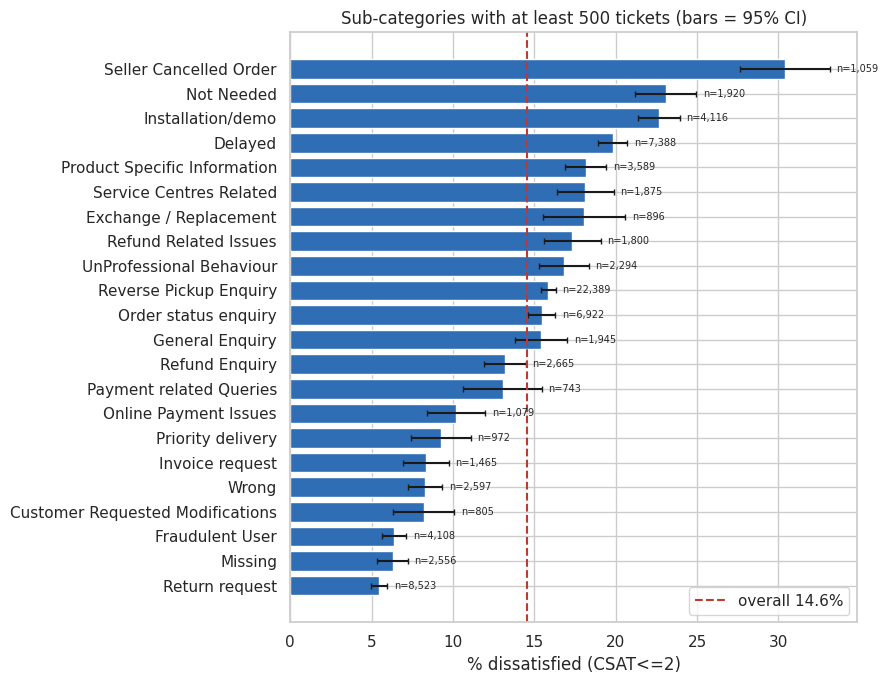

Sub-categories shown cover 95% of all tickets


In [34]:
# Chart - 20 visualization code
g = rate_table("Sub-category"); g = g[g.n >= 500].sort_values("rate")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(g.index, g["rate"] * 100, xerr=g["ci"] * 100, color=BLUE, capsize=2)
ax.axvline(GLOBAL_LOW * 100, color=RED, ls="--", label=f"overall {GLOBAL_LOW:.1%}")
for i, (v, n, c) in enumerate(zip(g["rate"] * 100, g.n, g["ci"] * 100)): ax.text(v + c + .4, i, f"n={n:,}", va="center", fontsize=7)
ax.set_xlabel("% dissatisfied (CSAT<=2)"); ax.set_title("Sub-categories with at least 500 tickets (bars = 95% CI)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Sub-categories shown cover {:.0%} of all tickets".format(g.n.sum() / len(eda)))

##### 1. Why did you pick the specific chart?

With 57 sub-categories, only a sorted horizontal bar of *rates* with confidence intervals and sample sizes lets us rank them fairly; sub-categories with fewer than 500 tickets are hidden because their rates are too noisy to trust.

##### 2. What is/are the insight(s) found from the chart?

The sub-category is a much sharper separator than the broad category (Chart 7). **Seller Cancelled Order is the worst (30.4 %, n=1,059), followed by Not Needed (23.1 %), Installation/demo (22.7 %) and Delayed (19.8 %, n=7,388).** At the other end, **Return request (5.5 %), Missing (6.3 %) and Fraudulent User (6.4 %)** are very low. The biggest sub-category, Reverse Pickup Enquiry (22,389 tickets), sits at 15.9 %, just above average.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** these are concrete, nameable problems to attack: seller-initiated cancellations, installation/demo scheduling and delayed orders all point to *fulfilment* failures rather than agent behaviour, so fixing them upstream (seller reliability, delivery promises, technician slots) removes the cause rather than the symptom. The very low rates for return requests show that the support process itself works when the customer gets what they asked for. **Negative:** Delayed (7.4k tickets at 19.8 %) and Reverse Pickup Enquiry (22.4k tickets at 15.9 %) generate the largest *absolute* number of unhappy customers because they are so frequent, so they matter more in total than the worst-rate sub-categories.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?

Recommendations are ordered by expected impact and by how directly the evidence supports them.

1. **Make first-response time the headline KPI (strongest evidence).** Dissatisfaction rises from 8.9 % (within 5 min) to 13.9 % (5-15 min), 20.3 % (15-60 min) and 36.3 % (beyond 24 h). Set an SLA of about 15 minutes, show ticket age on the supervisors' dashboard, and automatically escalate anything that passes 1 hour and especially 24 hours. Customers waiting more than a day are about four times as likely to be dissatisfied as those answered within 5 minutes.
2. **Fix the e-mail channel.** E-mail has 23.2 % dissatisfaction versus about 14 % on the phone, with the clearest gaps for returns (21.9 % vs 11-12 %) and payments (about 24 % vs 11 %). Review e-mail templates, ownership and turnaround, and avoid pushing customers to e-mail as a call-deflection tactic until it is fixed.
3. **Attack fulfilment failures at their source.** Seller Cancelled Order (30.4 %), Installation/demo (22.7 %), Not Needed (23.1 %) and Delayed (19.8 %) are fulfilment problems. Work with sellers and logistics (seller reliability scores, realistic delivery promises, technician slot booking) and give support agents proactive status information. Treat Furniture, Mobile and Home Appliances (about 30 % dissatisfied) as a priority group with dedicated handling.
4. **Support trainees and the Morning shift.** Agents on job training have 16.6 % dissatisfaction versus 12-14 % for other cohorts, and they handle about 30 % of the volume; route cancellation and order-related cases away from trainees, pair them with mentors and add post-training coaching (the >90-day cohort is no better than the 0-30-day one). The Morning shift is weak even for experienced agents (16.0 % vs 11.1 % for experienced Evening agents), so review its staffing, tooling and ticket mix.
5. **Spread best practice.** Agent-to-agent variation is about twice what chance would produce, and the manager spread is 11.3 % to 17.2 %; study the best teams (and the Split shift, 10.1 %), make the practices standard, and coach the high-dissatisfaction tail. Use ticket-mix-adjusted comparisons before any individual performance review.
6. **Find out what changed in the last ten days of August.** Dissatisfaction fell from about 15 % to about 13 % after 22-23 August. If that was a deliberate change, keep and extend it.
7. **Close the information gap.** Much of the dissatisfaction cannot be explained by ticket metadata. Capture an earlier voice-of-customer signal (a one-tap rating at ticket closure, chat sentiment) and then build the predictive model on it.

**Caveats to respect:** one month of data; category and sub-category comparisons with small samples (e.g. "Others", n=99) are shown with intervals and should not drive decisions; differences are associations, not proven causes, and shift, tenure and agent effects overlap.

# **Conclusion**

Shopzilla's satisfaction picture is polarised (69 % give 5, 13 % give 1) and about 14.6 % of tickets end in dissatisfaction. The analysis of 85,907 tickets shows that the largest and most actionable driver is **how long the customer waits for the first response**, followed by **channel (e-mail), the type of issue and product (seller cancellations, installation, bulky and high-value items), and people factors (trainees, Morning shift, individual agents and teams)**. Time of day and weekday matter very little. Satisfaction also improved during the month, which is worth understanding and preserving.

The practical message is that dissatisfaction is mostly an *operations* problem that can be reduced by faster first response, better e-mail handling, fixing fulfilment failures and targeted coaching, rather than a general service-attitude problem. The effects are associations from one month of data, not controlled experiments, and a large part of the variation is not explained by ticket metadata at all - so the recommended next step is to collect an earlier voice-of-customer signal and then build the prediction model on top of these findings.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***